In [119]:
import pandas as pd
import numpy as np
import seaborn as sns

In [120]:
df = pd.read_csv('data.csv')

In [121]:
string_columns = df.select_dtypes(include=['object', 'string']).columns
df[string_columns] = df[string_columns].apply(lambda col: col.str.lower().str.replace(' ', '_'))

df.columns = df.columns.str.lower().str.replace(' ', '_')

In [122]:
df['log_msrp'] = np.log1p(df.msrp)

In [123]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

In [2]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.4, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


print(f"train: {len(train_df)} ({len(train_df) / len(df):.0%})")
print(f"val:   {len(val_df)} ({len(val_df) / len(df):.0%})")
print(f"test:  {len(test_df)} ({len(test_df) / len(df):.0%})")

NameError: name 'df' is not defined

<Axes: xlabel='log_msrp', ylabel='Count'>

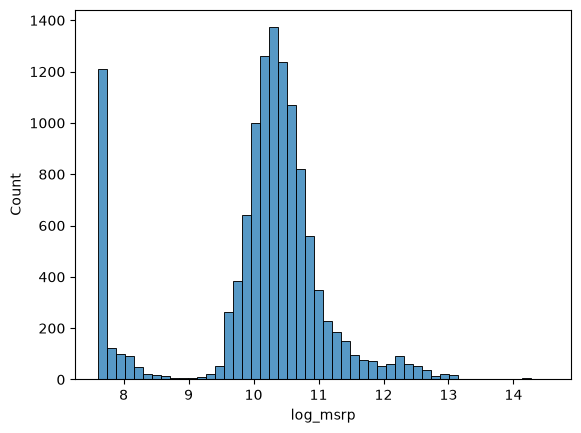

In [ ]:
sns.histplot(df.log_msrp, bins=50)

In [ ]:
y_train = np.log1p(train_df.msrp.values)
y_val = np.log1p(val_df.msrp.values)
y_test = np.log1p(test_df.msrp.values)


In [ ]:
base = ["engine_hp","engine_cylinders", "highway_mpg", "city_mpg", "popularity", "year"]
df.head().columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp', 'log_msrp'],
      dtype='str')

In [ ]:
X_train = train_df[base].values
X_train = train_df[base].fillna(0).values


In [ ]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    
    """
     First we transpose. Rows become columns and cols become rows.
     Then we multiply the new matrix with original
     Multiplication example:
    Example:

    A (2*3):
    A = [1 2 3]
        [4 5 6]
        
    B (3*2):
    B = [ 7  8]
        [ 9 10]
        [11 12]
    Result C = A·B will be (2*2).

    C[0][0] = (1·7) + (2·9) + (3·11) = 7 + 18 + 33 = 58
    C[0][1] = (1·8) + (2·10) + (3·12) = 8 + 20 + 36 = 64
    C[1][0] = (4·7) + (5·9) + (6·11) = 28 + 45 + 66 = 139
    C[1][1] = (4·8) + (5·10) + (6·12) = 32 + 50 + 72 = 154

    C = [ 58  64]
        [139 154]
    """
    XTX = X.T.dot(X)

    # There is no division in general. There is only multiplication with 
    # the numbers inverse: 4 / 2 == 4 * 2 ** (-1)
    
    # The magic formula called the normal equation: 
    # X^T X w = X^T y
    
    # Also, it's a coincidence that X^T for matrixes X.T also creates a 
    # square matrix for which we have a inverse (or maybe not a surprise)
    
    # To isolate w, you multiply both sides on the left by (X^T X)^{-1}:
    # (X^T X)^{-1} (X^T X) w = (X^T X)^{-1} X^T y
    # w = (X^T X)^{-1} X^T y
    
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]
# train_df.T.dot(train_df)

In [ ]:
w0 , w = train_linear_regression(X_train, y_train)

In [ ]:
y_pred = w0 + X_train.dot(w)

<Axes: ylabel='Count'>

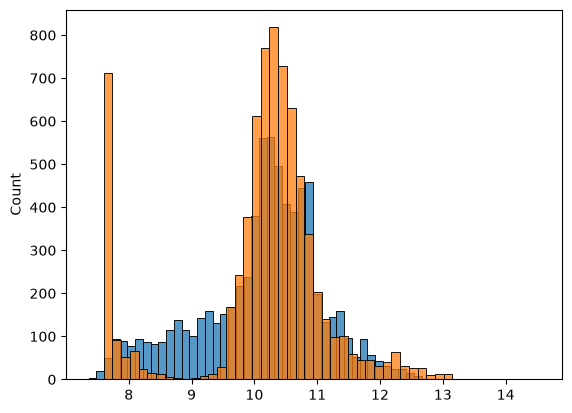

In [ ]:
sns.histplot(y_pred, bins=50)
sns.histplot(y_train , bins=50)


In [ ]:
def rmse(y_pred, y):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [ ]:
rmse(y_train, y_pred)

np.float64(0.5226882370086212)

In [ ]:
def prepare_X(df, base=base):
    df.copy()

    df['age'] = 2017 - df.year
    
    features = base.copy()
    features.append('age')
    
    
    for x in [2,3,4]:    
        df["number_of_doors_%s" % x] = (df.number_of_doors == x).astype('int')
        features.append("number_of_doors_%s" % x)
    
    
    most_popular = list(df.make.value_counts().head().index)
    all_make = set(df.make.values)
    
    for x in most_popular:    
        df["make_%s" % x] = (df.number_of_doors == x).astype('int')
        features.append("make_%s" % x)
        
    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
        
        
    return X

NameError: name 'base' is not defined

In [ ]:
X_train = prepare_X(train_df)

w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(val_df)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

In [ ]:
list(df.make.value_counts().head().index)

['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']